# 02 — Exploratory analysis

**Question for this notebook:** what do the earthquake rate and the ground uplift look like over time, and how do they relate? This is looking before modelling. It does not measure forecasting skill: that comes in phase 7, with time-ordered splits.

**Plan:**
1. Event rate over time. *(this step)*
2. Uplift and uplift rate over time.
3. Uplift against cumulative event count (the paper's central relationship).
4. Event rate against uplift rate, including lags.
5. The M ≥ 3 events.
6. Map of events and GPS stations.

Throughout, "M ≥ 0.6" means events with Md (binned to 0.1) of at least `MC_MAIN` = 0.6, the magnitude of completeness chosen in `01_completeness`. Counts above Mc are comparable across years; counts of *all* events partly track the growth of the seismic network.

In [1]:
import matplotlib.patheffects as patheffects
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.completeness import MC_MAIN, bin_magnitudes
from src.basemap import DEFAULT_LABELS, draw_basemap, load_osm_features
from src.gps import distance_km, load_station_coordinates
from src.series import event_counts, on_weekday, period_start, station_daily, trailing_rate

events = pd.read_parquet("../data/processed/catalogue.parquet")
gps = pd.read_parquet("../data/processed/gps_daily.parquet")

# The last weeks of the catalogue are incomplete: the final bulletin lags a few weeks
# (last fully reviewed month: August 2026). Shade them on plots; leave them out of anything quantitative.
INCOMPLETE_FROM = pd.Timestamp("2026-09-01", tz="UTC")
FIGURES = "../reports/figures/"  # figures used in the README
print(f"Events: {events['time'].min():%Y-%m-%d} to {events['time'].max():%Y-%m-%d}")
print(f"GPS:    {gps['date'].min():%Y-%m-%d} to {gps['date'].max():%Y-%m-%d}")

Events: 2005-03-22 to 2026-10-21
GPS:    2000-01-01 to 2025-12-31


## 1. Event rate over time

Monthly event counts, for all events and for M ≥ 0.6, on a log scale. Months with no events can't be drawn on a log scale, so they show as gaps. (Weekly counts, which the targets will use, are summarised in the table below.)

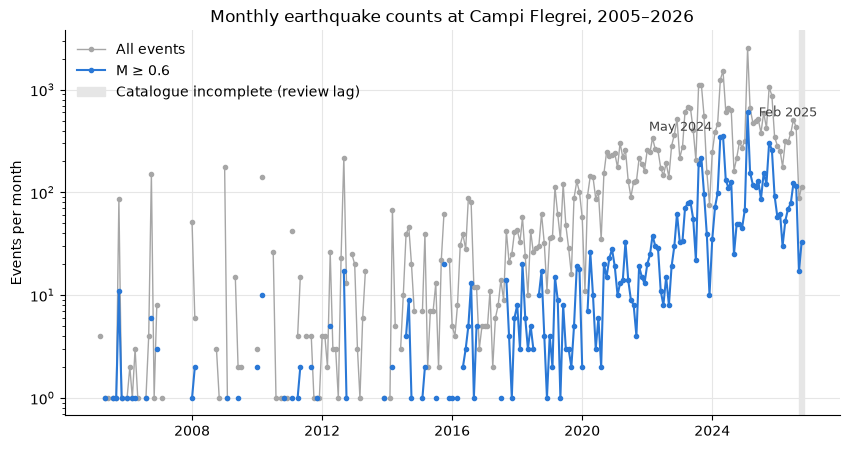

In [2]:
monthly_all = event_counts(events, "M", start="2005-01-01", end="2026-10-21")
monthly_mc = event_counts(events, "M", mc=MC_MAIN, start="2005-01-01", end="2026-10-21")
weekly_mc = event_counts(events, "W", mc=MC_MAIN, start="2005-01-03", end="2026-10-21")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly_all.index, monthly_all.where(monthly_all > 0), marker="o", markersize=3,
        linewidth=1, color="0.65", label="All events")
ax.plot(monthly_mc.index, monthly_mc.where(monthly_mc > 0), marker="o", markersize=3,
        linewidth=1.5, color="#2a78d6", label=f"M ≥ {MC_MAIN}")
ax.axvspan(INCOMPLETE_FROM, monthly_all.index[-1] + pd.Timedelta(days=31), color="0.9",
           label="Catalogue incomplete (review lag)")

# Label two of the busiest swarms (placed by hand so the labels don't collide).
for month, offset in [("2025-02-01", (8, 0)), ("2024-05-01", (-8, 6))]:
    month = pd.Timestamp(month, tz="UTC")
    ax.annotate(f"{month:%b %Y}", (month, monthly_mc[month]), textcoords="offset points",
                xytext=offset, ha="left" if offset[0] > 0 else "right", va="center",
                fontsize=9, color="0.25")

ax.set_yscale("log")
ax.set_ylabel("Events per month")
ax.set_title("Monthly earthquake counts at Campi Flegrei, 2005–2026")
ax.grid(True, which="major", color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIGURES + "event_rate_monthly.png", dpi=150, bbox_inches="tight")
plt.show()

How often is a week empty? This matters for the weekly-count target in phase 6: a series that is almost all zeros behaves very differently from one with tens of events a week.

In [3]:
complete = weekly_mc[weekly_mc.index < INCOMPLETE_FROM]
by_year = complete.groupby(complete.index.year).agg(
    weeks="size",
    events="sum",
    share_of_weeks_with_none=lambda s: (s == 0).mean(),
    median_per_week="median",
    max_per_week="max",
)
by_year.round(2)

,weeks,events,share_of_weeks_with_none,median_per_week,max_per_week
period_start,,,,,
2005,52,15,0.90,0.0,11
2006,52,13,0.88,0.0,6
2007,53,1,0.98,0.0,1
2008,52,2,0.96,0.0,1
2009,52,2,0.96,0.0,1
2010,52,13,0.94,0.0,10
2011,52,7,0.90,0.0,2
2012,53,23,0.91,0.0,13
2013,52,1,0.98,0.0,1


**What plot 1 shows:**

- **Two regimes.** Until about 2016, events with M ≥ 0.6 are rare: most months have none or one, with occasional short bursts (for example late 2005, 2012). From 2017–2018 the rate climbs steadily, from about 7 a month in 2018 to about 180 a month in 2025: roughly a doubling every 1.5 years, a straight-ish line on the log scale.
- **Swarms on top of the trend.** The busiest months are swarms around the larger earthquakes: May 2024 (the Md 4.4) and February 2025 (600 events at M ≥ 0.6 in one month).
- **2026 is quieter than 2025** (about 17 events a week at M ≥ 0.6 against 42), even before the incomplete last weeks (shaded).
- **For the weekly target (phase 6):** before 2018, 73–98% of weeks have no event at M ≥ 0.6; from 2023 almost every week has some, with a median of 10–27. A model has to handle both: a count model that allows many zeros (Poisson or negative binomial), and an evaluation that reports early and recent years separately. We may decide to train only from about 2018, where there is enough signal; that's a phase 6 decision.

## 2. Uplift and uplift rate over time

**Which stations have data when?** The 21 GPS stations started in different years. The chart shows, for each month, the share of days with a GPS solution. Stations are sorted by how much they rose from January 2018 to the end of their record, a rough proxy for distance from the centre of uplift at Pozzuoli.

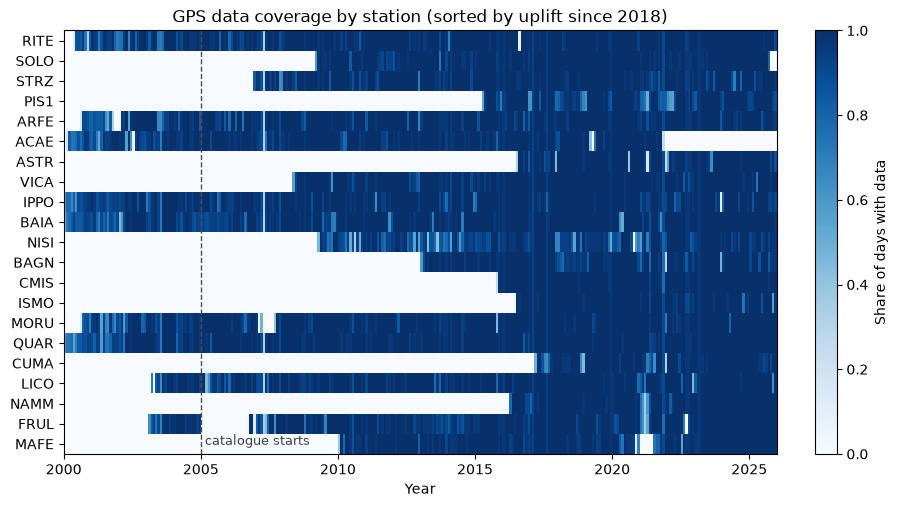

In [4]:
uplift_since_2018 = (
    gps.sort_values("date").groupby("station", observed=True)["up"].last()
    - gps[(gps["date"] >= "2018-01-01") & (gps["date"] < "2018-02-01")]
      .groupby("station", observed=True)["up"].mean()
)
order = uplift_since_2018.sort_values(ascending=False).index.tolist()

months = pd.date_range("2000-01-01", "2025-12-01", freq="MS", tz="UTC")
coverage = (
    gps.assign(month=period_start(gps["date"], "M"))
    .groupby(["station", "month"], observed=True).size()
    .unstack("month").reindex(index=order, columns=months).fillna(0)
    / months.days_in_month.values
)

fig, ax = plt.subplots(figsize=(10, 5.5))
image = ax.imshow(coverage.values, aspect="auto", cmap="Blues", vmin=0, vmax=1,
                  extent=[months[0].year, months[-1].year + 1, len(order), 0],
                  interpolation="nearest")
ax.set_yticks(np.arange(len(order)) + 0.5, order)
ax.axvline(2005, color="0.3", linewidth=1, linestyle="--")
ax.text(2005.15, len(order) - 0.3, "catalogue starts", fontsize=9, color="0.25", va="bottom")
ax.set_xlabel("Year")
ax.set_title("GPS data coverage by station (sorted by uplift since 2018)")
fig.colorbar(image, ax=ax, label="Share of days with data", fraction=0.03)
plt.show()

**Uplift and its rate.** Five stations with long records, from the centre outwards: RITE (Pozzuoli, the largest uplift), ARFE, IPPO, QUAR and LICO (far away). Positions are vertical displacement relative to each station's mean in January 2005, when the catalogue starts.

The rate is the slope of a straight line fitted to the previous 90 days (`trailing_rate`). Daily GPS heights are too noisy (about ±10 mm) to difference day by day. The window is *trailing*: each day's rate uses only data up to that day, so the same function can later give forecasting features without looking into the future.

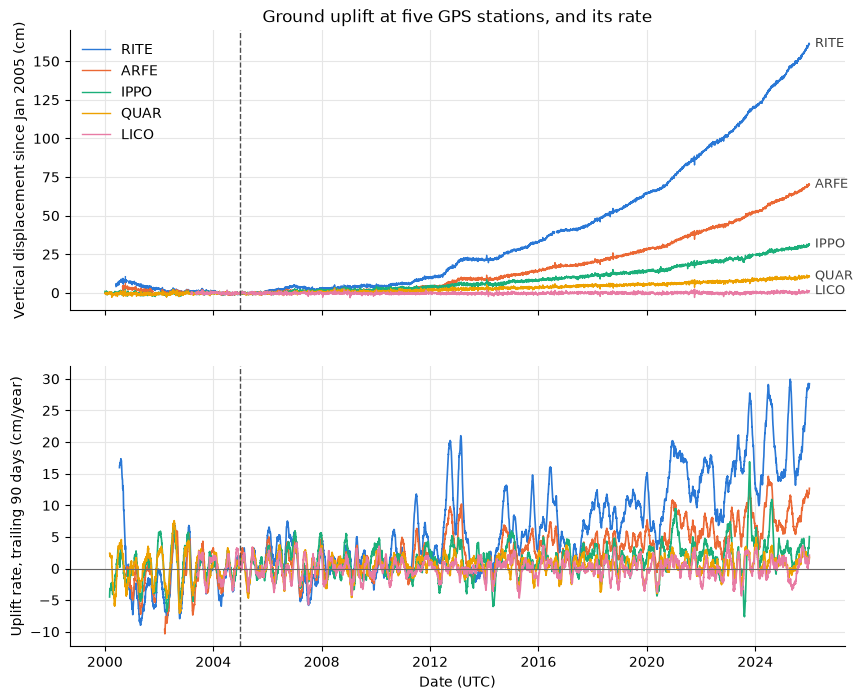

In [5]:
stations = ["RITE", "ARFE", "IPPO", "QUAR", "LICO"]
station_colours = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]

fig, (ax_up, ax_rate) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
for station, colour in zip(stations, station_colours):
    up = station_daily(gps, station)
    up_cm = (up - up["2005-01"].mean()) * 100
    ax_up.plot(up_cm.index, up_cm, linewidth=1, color=colour, label=station)
    ax_up.annotate(station, (up_cm.dropna().index[-1], up_cm.dropna().iloc[-1]),
                   textcoords="offset points", xytext=(4, 0), va="center", fontsize=9, color="0.25")
    ax_rate.plot(up.index, trailing_rate(up, 90) * 100, linewidth=1.2, color=colour, label=station)

ax_up.set_ylabel("Vertical displacement since Jan 2005 (cm)")
ax_up.set_title("Ground uplift at five GPS stations, and its rate")
ax_up.legend(frameon=False, loc="upper left")
ax_rate.axhline(0, color="0.4", linewidth=0.8)
ax_rate.set_ylabel("Uplift rate, trailing 90 days (cm/year)")
ax_rate.set_xlabel("Date (UTC)")
for ax in (ax_up, ax_rate):
    ax.axvline(pd.Timestamp("2005-01-01", tz="UTC"), color="0.3", linewidth=1, linestyle="--")
    ax.grid(True, which="major", color="0.9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

**The same uplift on a logarithmic scale.** On a log scale, steady *exponential* growth is a straight line, and the slope gives the doubling time. Displacements at or below 1 cm are left out: they are within GPS noise, and zero or negative values can't be shown on a log scale. LICO is left out because it barely moves.

*Caveat:* the "zero" here is each station's position in January 2005, which is an arbitrary choice. A different start date shifts all values and bends the early part of the curve, so only the later, larger part of each curve is meaningful on this scale.

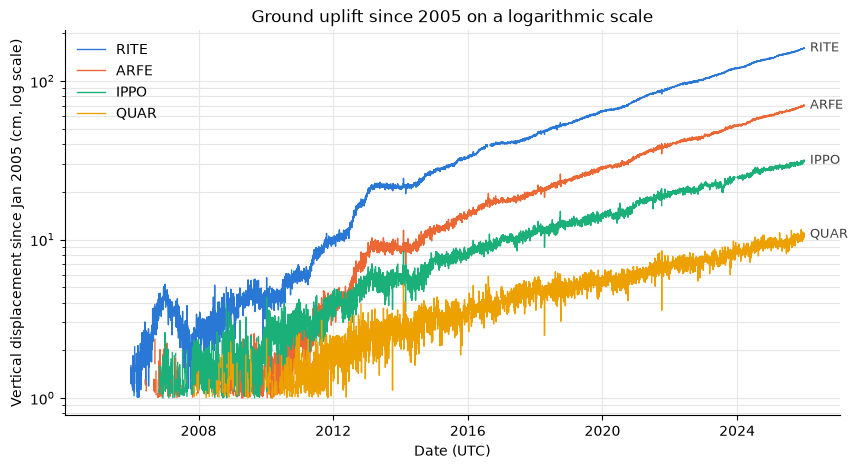

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
for station, colour in zip(stations[:4], station_colours[:4]):
    up = station_daily(gps, station)
    up_cm = (up - up["2005-01"].mean()) * 100
    up_cm = up_cm["2005":].where(up_cm > 1)
    ax.plot(up_cm.index, up_cm, linewidth=1, color=colour, label=station)
    last = up_cm.dropna()
    ax.annotate(station, (last.index[-1], last.iloc[-1]), textcoords="offset points",
                xytext=(4, 0), va="center", fontsize=9, color="0.25")

ax.set_yscale("log")
ax.set_ylabel("Vertical displacement since Jan 2005 (cm, log scale)")
ax.set_xlabel("Date (UTC)")
ax.set_title("Ground uplift since 2005 on a logarithmic scale")
ax.grid(True, which="both", color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.show()

In [7]:
# Doubling time of RITE's uplift: fit a straight line to log(uplift) over several periods.
rite = station_daily(gps, "RITE")
rite_cm = ((rite - rite["2005-01"].mean()) * 100).dropna()
rows = {}
for start, end in [("2012", "2025"), ("2012", "2017"), ("2018", "2021"), ("2022", "2025")]:
    part = rite_cm[start:end]
    years = (part.index - part.index[0]).days / 365.25
    slope = np.polyfit(years, np.log(part.values), 1)[0]  # growth rate per year (natural log)
    rows[f"{start}–{end}"] = {"uplift at start (cm)": round(part.iloc[:30].mean(), 1),
                              "uplift at end (cm)": round(part.iloc[-30:].mean(), 1),
                              "doubling time (years)": round(np.log(2) / slope, 1)}
pd.DataFrame(rows).T

,uplift at start (cm),uplift at end (cm),doubling time (years)
2012–2025,10.0,160.2,4.0
2012–2017,10.0,45.2,3.1
2018–2021,45.9,89.3,4.2
2022–2025,90.7,160.2,4.7


**What the log plot shows:**

- **From about 2013 the curves are close to straight lines: the uplift grows roughly exponentially.** At RITE it doubled about every 4 years from 2012 to 2025 (10 cm to 160 cm).
- **The doubling time is slowly getting longer:** about 3 years in 2012–2017, 4.2 in 2018–2021 and 4.7 in 2022–2025. So the growth is now a little slower than exponential, even though the uplift rate in cm/year is still rising.
- **The stations run roughly parallel** from 2013 on: they grow by about the same factor, with RITE (160 cm by 2025) about 2.3 times ARFE, 5 times IPPO and 15 times QUAR. That fits one source whose shape stays the same while its strength grows. It also suggests that for forecasting, several stations may carry largely the same information as RITE alone, apart from noise.
- **2012–2013 stands out** as a fast step at RITE, ARFE and IPPO, and before about 2011 the curves are mostly noise (uplift of only a few cm).

The exponential look depends on the January 2005 zero point (see caveat above), so these doubling times describe this choice of reference, not a physical constant.

In [8]:
# Uplift rate at RITE by year (cm/year): mean of the daily 90-day rates.
rite_rate = trailing_rate(station_daily(gps, "RITE"), 90) * 100
rite_rate["2005":].groupby(rite_rate["2005":].index.year).mean().round(1).rename("RITE cm/year").to_frame()

,RITE cm/year
date,
2005,0.6
2006,3.8
2007,-1.7
2008,1.2
2009,0.7
2010,1.7
2011,3.8
2012,7.4
2013,4.4


**What plot 2 shows:**

- **Coverage.** Only 9 stations have data from before 2005: seven since 2000 (RITE, ARFE, ACAE, IPPO, BAIA, MORU, QUAR) and LICO and FRUL since 2003. The other 12 start between 2006 and 2017. ACAE stops in November 2021 and SOLO in September 2025; FRUL has a gap in 2005–2006 and MAFE one in 2021. So any feature that uses *all 21 stations* only exists from 2017; before that, features must rely on the long-record stations, or handle missing stations.
- **Uplift accelerates.** RITE rose about 160 cm since January 2005, almost all of it after 2011. Its rate climbs from near zero in 2005–2010 to about 10 cm/year in 2018–2020 and about 18–21 cm/year in 2023–2025 (table). Other stations follow the same shape, scaled down with distance: ARFE about 70 cm, IPPO 30, QUAR 10, LICO almost nothing. That common shape is expected if one source under Pozzuoli drives all of them.
- **The rate comes in pulses**, not as a smooth curve: at RITE there are bursts to 20–30 cm/year in 2012–2013, 2020–2021 and repeatedly in 2023–2025. Whether those pulses line up with seismic swarms is the question for plot 4.
- **Noise.** At far stations the 90-day rate wobbles by about ±5 cm/year around zero, with similar wiggles at all stations in the early years (probably seasonal or network-wide effects). So rates from far stations carry little signal on their own; differences between stations, or a longer window, may help. That's a feature-engineering question for phase 6.

## 3. Uplift against cumulative event count

The paper's central observation: plotted against the uplift at RITE, the cumulative number of earthquakes grows in a regular way, which its epidemic model then explains. Here we draw that relationship three ways:

- **Ours:** all events with M ≥ 0.6 (`MC_MAIN`), located or not, 2005 to the end of the GPS record (December 2025).
- **The paper's, as we reconstruct it:** located events with M > 0.5, January 2005 to June 2024 (section 5 of `01_completeness`). Because magnitudes are binned to 0.1, "M > 0.5" is the same set as M ≥ 0.6.
- **The paper's, other reading:** located events with M ≥ 0.5.

The x axis is RITE's vertical displacement since January 2005, smoothed with a 15-day centred median (gaps interpolated) to remove daily GPS noise. Centring uses a week of future data, which is fine for a picture but not for a forecasting feature.

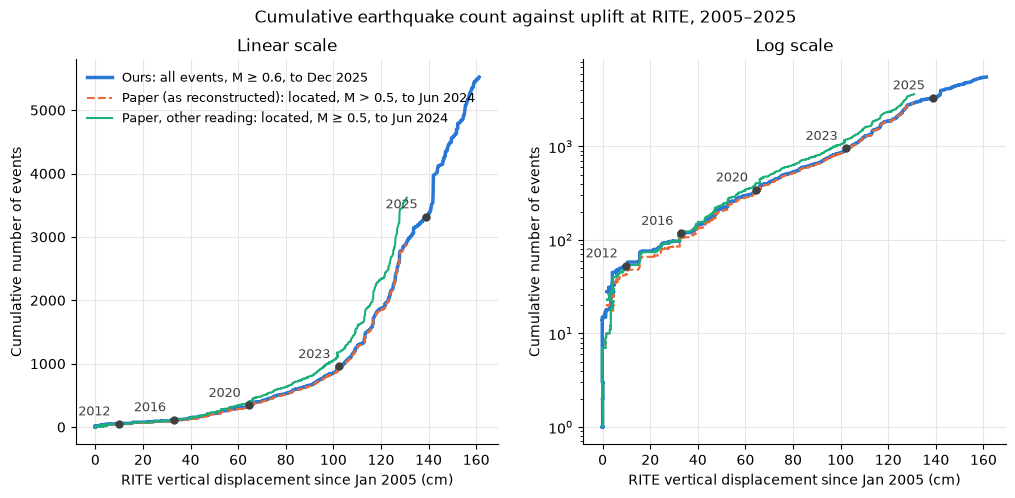

In [9]:
rite = station_daily(gps, "RITE")
rite_cm = ((rite - rite["2005-01"].mean()) * 100).interpolate(limit_area="inside")
rite_smooth = rite_cm.rolling(15, center=True, min_periods=5).median()

located = events[events["has_location"]]
curves = {
    f"Ours: all events, M ≥ {MC_MAIN}, to Dec 2025":
        event_counts(events, "D", mc=MC_MAIN, start="2005-01-01", end="2025-12-31").cumsum(),
    "Paper (as reconstructed): located, M > 0.5, to Jun 2024":
        event_counts(located, "D", mc=0.6, start="2005-01-01", end="2024-06-30").cumsum(),
    "Paper, other reading: located, M ≥ 0.5, to Jun 2024":
        event_counts(located, "D", mc=0.5, start="2005-01-01", end="2024-06-30").cumsum(),
}
curve_styles = [dict(color="#2a78d6", linewidth=2.5),
                dict(color="#eb6834", linewidth=1.5, linestyle="--"),
                dict(color="#1baf7a", linewidth=1.5)]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, scale in zip(axes, ["linear", "log"]):
    for (label, cum), style in zip(curves.items(), curve_styles):
        x = rite_smooth.reindex(cum.index)
        ax.plot(x, cum.where(cum > 0), label=label, **style)
    # Mark the start of some years along our curve, to show where time is on this axis.
    ours = curves[next(iter(curves))]
    for year in [2012, 2016, 2020, 2023, 2025]:
        day = pd.Timestamp(f"{year}-01-01", tz="UTC")
        ax.plot(rite_smooth[day], ours[day], marker="o", markersize=5, color="0.25")
        ax.annotate(str(year), (rite_smooth[day], ours[day]), textcoords="offset points",
                    xytext=(-6, 6), ha="right", fontsize=9, color="0.25")
    ax.set_yscale(scale)
    ax.set_xlabel("RITE vertical displacement since Jan 2005 (cm)")
    ax.set_ylabel("Cumulative number of events")
    ax.set_title(f"{scale.capitalize()} scale")
    ax.grid(True, which="major", color="0.9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, loc="upper left", fontsize=9)
fig.suptitle("Cumulative earthquake count against uplift at RITE, 2005–2025")
fig.savefig(FIGURES + "cumulative_count_vs_uplift.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# The three curves at a few dates.
dates = ["2010-01-01", "2014-01-01", "2018-01-01", "2022-01-01", "2024-06-30", "2025-12-31"]
table = pd.DataFrame({"RITE uplift (cm)": rite_smooth.reindex(pd.to_datetime(dates, utc=True)).round(1).values},
                     index=dates)
for label, cum in curves.items():
    table[label.split(":")[0]] = cum.reindex(pd.to_datetime(dates, utc=True)).values
table

,RITE uplift (cm),Ours,Paper (as reconstructed),"Paper, other reading"
2010-01-01,4.0,33,25.0,29.0
2014-01-01,21.1,77,66.0,74.0
2018-01-01,45.4,175,161.0,188.0
2022-01-01,89.6,657,642.0,797.0
2024-06-30,130.8,2913,2893.0,3620.0
2025-12-31,161.2,5523,NaN,NaN


In [11]:
# On the log scale, how close is our curve to a straight line? Fit log10(N) = a + c * uplift
# from 2013, when the uplift is well above GPS noise.
part = pd.DataFrame({"uplift": rite_smooth, "n": ours})["2013":"2025-12-31"].dropna()
c, a = np.polyfit(part["uplift"], np.log10(part["n"]), 1)
residual = np.log10(part["n"]) - (a + c * part["uplift"])
print(f"log10(N) rises by {c:.4f} per cm: N grows tenfold every {1 / c:.0f} cm of uplift at RITE.")
print(f"Residuals: typical (std) {residual.std():.2f}, largest {residual.abs().max():.2f} (in log10 units).")

log10(N) rises by 0.0137 per cm: N grows tenfold every 73 cm of uplift at RITE.
Residuals: typical (std) 0.03, largest 0.08 (in log10 units).


**What plot 3 shows:**

- **Our curve and the paper's are almost the same.** By June 2024 we count 2,913 events and the reconstructed paper set 2,893. Nearly every event with M ≥ 0.6 has a location, so leaving out unlocated events (the worry from section 5 of `01_completeness`) hardly matters above Mc: unlocated events are almost all below Md 1. What does matter is how "larger than 0.5" is read: M ≥ 0.5 gives 3,620 events by June 2024, about 25% more, and a curve that pulls away from 2020 on.
- **Since about 2012, log(N) rises almost linearly with uplift.** The fit gives a tenfold increase in the cumulative count for every 73 cm of uplift at RITE, with residuals of only about 0.03 in log₁₀ (7%). Before 2012 the uplift is within a few cm of zero, so the x position is mostly GPS noise.
- **Swarms show as vertical steps**: many events with little extra uplift, for example around 135 cm (May 2024, the Md 4.4) and 140 cm (February 2025). Between swarms the curve rises more gently. The paper's epidemic model is built to describe this pattern: uplift loads the system, and earthquakes trigger further earthquakes in short cascades.
- **A hint for forecasting (phase 6).** If N grows like 10^(uplift / 73 cm), then the event rate is proportional to N × uplift rate: the same uplift produces more earthquakes now than ten years ago. So the cumulative count (or recent rate) multiplied by the uplift rate is a natural candidate feature, and a model that only sees the uplift rate will miss this. This is a hypothesis to test, not a result: plot 4 is the first look.
- Caveat: these are cumulative curves, which always look smooth; a straight line here can hide a lot of week-to-week variation in rate.

## 4. Weekly event rate against uplift rate

Plot 3 compared running totals. Here we compare *rates*, week by week: the number of events with M ≥ 0.6 in each week, against RITE's uplift rate. We use 2013–2025: before 2013 the uplift rate is mostly GPS noise, and the GPS record ends in December 2025.

Counts are shown as log₁₀(count + 1): the +1 keeps empty weeks, and the log stops the few huge swarm weeks from dominating.

**4a. All weeks together.** Each dot is one week; colour shows the year. The uplift rate is the trailing 90-day rate at the end of the week (Sunday).

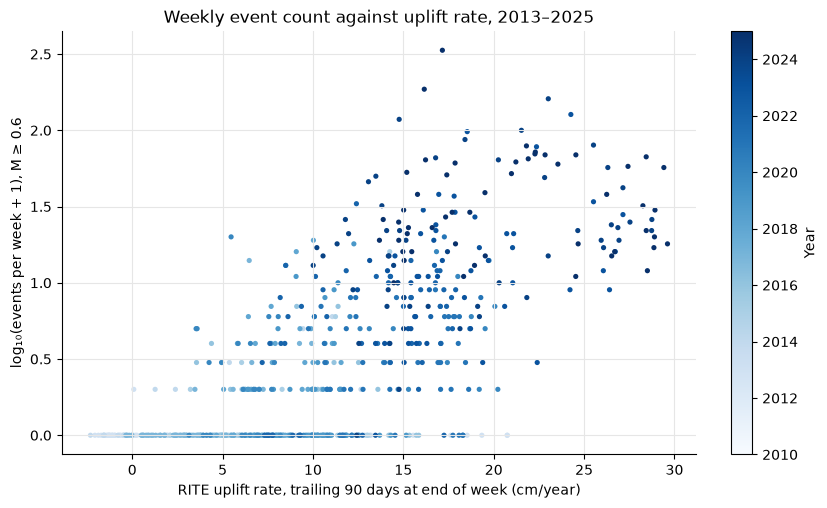

Correlation over all weeks: 0.71


In [12]:
weeks_wk = event_counts(events, "W", mc=MC_MAIN, start="2013-01-07", end="2025-12-28")
log_count = np.log10(weeks_wk + 1).rename("log10(count + 1)")
rite = station_daily(gps, "RITE")
rate_90_sun = on_weekday(trailing_rate(rite, 90) * 100, weeks_wk.index, 6)

fig, ax = plt.subplots(figsize=(9, 5.5))
points = ax.scatter(rate_90_sun, log_count, c=weeks_wk.index.year, cmap="Blues", vmin=2010,
                    s=14, edgecolors="none")
ax.set_xlabel("RITE uplift rate, trailing 90 days at end of week (cm/year)")
ax.set_ylabel(f"log₁₀(events per week + 1), M ≥ {MC_MAIN}")
ax.set_title("Weekly event count against uplift rate, 2013–2025")
ax.grid(True, which="major", color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
fig.colorbar(points, ax=ax, label="Year", fraction=0.04)
plt.show()
print(f"Correlation over all weeks: {rate_90_sun.corr(log_count):.2f}")

**4b. Does the uplift rate lead the event rate?** We correlate the uplift rate in week *t* with the count in week *t + k*, for lags *k* from −12 to +12 weeks. A peak at positive *k* would mean uplift-rate changes come *before* changes in seismicity, which is what forecasting needs.

Two traps:

1. **Shared trend.** Both series rise from 2013 to 2025, so they correlate at every lag just because of that. To see whether short-term *pulses* line up, we also remove each series' 52-week centred moving average and correlate what is left ("de-trended").
2. **Window timing.** A trailing 90-day rate measured on Sunday describes, on average, the uplift about 6 weeks earlier. That shifts any peak by about −6 weeks. To get the timing right we use a 28-day rate *centred* on the middle of each week (Thursday). Centring uses two weeks of future data: fine for this diagnosis, not as a forecasting feature.

Neighbouring weeks are strongly correlated with each other, so the effective sample is much smaller than the 678 weeks; treat differences below about 0.1 as noise.

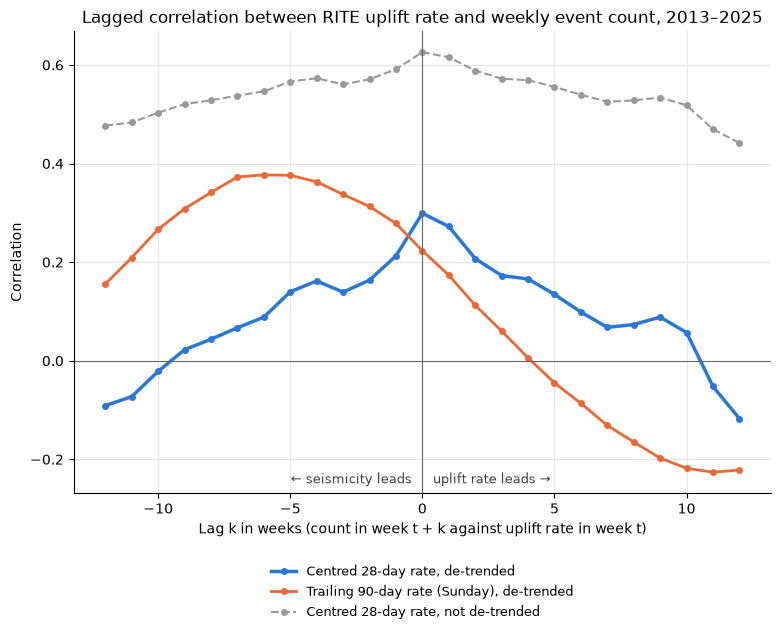

,"Centred 28-day rate, de-trended","Trailing 90-day rate (Sunday), de-trended","Centred 28-day rate, not de-trended"
lag k (weeks),,,
-3,0.14,0.34,0.56
-2,0.16,0.31,0.57
-1,0.21,0.28,0.59
0,0.30,0.22,0.63
1,0.27,0.17,0.62
2,0.21,0.11,0.59
3,0.17,0.06,0.57


In [13]:
def detrend(series):
    return series - series.rolling(52, center=True, min_periods=26).mean()

# The 28-day trailing rate, moved back 14 days, is the rate over 28 days centred on each day.
rate_28_centred = on_weekday((trailing_rate(rite, 28) * 100).shift(-14), weeks_wk.index, 3)

lags = np.arange(-12, 13)
lagged = pd.DataFrame({
    "Centred 28-day rate, de-trended": [detrend(rate_28_centred).corr(detrend(log_count).shift(-k)) for k in lags],
    "Trailing 90-day rate (Sunday), de-trended": [detrend(rate_90_sun).corr(detrend(log_count).shift(-k)) for k in lags],
    "Centred 28-day rate, not de-trended": [rate_28_centred.corr(log_count.shift(-k)) for k in lags],
}, index=pd.Index(lags, name="lag k (weeks)"))

fig, ax = plt.subplots(figsize=(9, 6))
styles = [dict(color="#2a78d6", linewidth=2.5), dict(color="#eb6834", linewidth=2),
          dict(color="0.6", linewidth=1.5, linestyle="--")]
for (label, values), style in zip(lagged.items(), styles):
    ax.plot(lagged.index, values, marker="o", markersize=4, label=label, **style)
ax.axhline(0, color="0.4", linewidth=0.8)
ax.axvline(0, color="0.4", linewidth=0.8)
ax.text(0.4, ax.get_ylim()[0] + 0.02, "uplift rate leads →", fontsize=9, color="0.25")
ax.text(-0.4, ax.get_ylim()[0] + 0.02, "← seismicity leads", fontsize=9, color="0.25", ha="right")
ax.set_xlabel("Lag k in weeks (count in week t + k against uplift rate in week t)")
ax.set_ylabel("Correlation")
ax.set_title("Lagged correlation between RITE uplift rate and weekly event count, 2013–2025")
ax.grid(True, which="major", color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.13), fontsize=9)
plt.show()
lagged.loc[-3:3].round(2)

**4c. Does the same uplift produce more earthquakes now?** Plot 3 suggested that the event rate is proportional to the cumulative count N times the uplift rate. If so, the number of events per cm of uplift should grow in proportion to N. Per year from 2013: events with M ≥ 0.6, RITE uplift in cm, their ratio, and N at the start of the year.

In [14]:
yearly = pd.DataFrame({
    "events": weeks_wk.groupby(weeks_wk.index.year).sum(),
    "uplift_cm": rite_smooth.groupby(rite_smooth.index.year).last().diff(),
    "N_at_start": ours.groupby(ours.index.year).first(),
}).loc[2013:2025]
yearly["events_per_cm"] = yearly["events"] / yearly["uplift_cm"]
yearly["events_per_cm / N_at_start"] = yearly["events_per_cm"] / yearly["N_at_start"]
yearly.round(2)

,events,uplift_cm,N_at_start,events_per_cm,events_per_cm / N_at_start
2013,1.0,1.98,76.0,0.50,0.01
2014,16.0,5.92,77.0,2.70,0.04
2015,25.0,6.20,93.0,4.03,0.04
2016,31.0,7.58,118.0,4.09,0.03
2017,26.0,4.66,149.0,5.58,0.04
2018,83.0,8.71,175.0,9.53,0.05
2019,86.0,10.41,255.0,8.26,0.03
2020,148.0,10.81,344.0,13.69,0.04
2021,165.0,14.32,489.0,11.52,0.02
2022,299.0,12.14,657.0,24.62,0.04


**What plot 4 shows:**

- **Faster uplift goes with more earthquakes (4a).** Over all weeks the correlation is 0.71: weeks with uplift rates above 20 cm/year typically have 10–100 events at M ≥ 0.6, weeks below 5 cm/year mostly none. But much of this is the shared trend: later years have both faster uplift and more events (dark dots top right).
- **Short-term pulses line up, at the same time (4b).** After removing the trend, the centred 28-day uplift rate correlates best with the count in the *same* week (0.30), slightly more with the following week (0.27) than the preceding one (0.21). So bursts of uplift and bursts of seismicity happen together; at most the uplift leads by about a week. There is no sign of uplift-rate changes arriving weeks or months ahead of seismicity.
- **The trailing 90-day rate peaks at about −5 weeks**, as expected from its window (it describes the uplift about 6 weeks before the Sunday it is measured on). As a forecasting feature, its de-trended correlation with *next* week's count is 0.17, with the count two weeks later 0.11, falling to zero by 4 weeks. So the short-term information in the uplift rate is modest and short-lived. Most of what it offers a forecast is the slow trend.
- **The same uplift produces ever more earthquakes (4c).** Events per cm of RITE uplift rose from about 3 (2014) to about 98 (2025), and roughly in step with the cumulative count N: their ratio stays between 0.02 and 0.05 from 2014 to 2025 while events per cm grow 36-fold and N 43-fold. This supports the hypothesis from plot 3, rate ∝ N × uplift rate, at the yearly scale.

**Implications for phase 6:**

- Strong candidate features: recent event counts (they carry the trend and the swarm clustering), and the product of recent count and uplift rate.
- The uplift rate on its own adds a little, mostly at 1–2 weeks ahead. A short, recent window will matter more than a long one.
- A fair baseline must include the trend and recent counts; beating "persistence" (next week = this week) will be the real test of whether GPS helps.

## 5. The M ≥ 3 events

The second forecasting target is the probability of at least one M ≥ 3 earthquake in the next 7 days. How many such events are there, when do they happen, and what were the event rate and uplift rate doing at the time? Magnitudes are binned to 0.1 as elsewhere, so "M ≥ 3" includes Md 2.95–2.99 (one event).

We show 2018 to August 2026 (the last complete month): there are no M ≥ 3 events before 2019. The GPS record ends in December 2025.

In [15]:
m_binned = bin_magnitudes(events["md"])
big = events[m_binned >= 3.0 - 1e-9]
medium = events[(m_binned >= 2.5 - 1e-9) & (m_binned < 3.0 - 1e-9)]
print(f"{len(big)} events with M ≥ 3, from {big['time'].min():%Y-%m-%d} to {big['time'].max():%Y-%m-%d}; "
      f"all located, all Bollettino: {big['has_location'].all()}, {(big['level'] == 'Bollettino').all()}")

end_complete = "2026-08-30"
weeks_18 = event_counts(events, "W", mc=MC_MAIN, start="2018-01-01", end=end_complete)
big_weeks = event_counts(big, "W", start="2018-01-01", end=end_complete)
print(f"Weeks from 2019 to Aug 2026: {(weeks_18.index >= '2019-01-01').sum()}, "
      f"of which {(big_weeks > 0).sum()} contain at least one M ≥ 3 event.")

91 events with M ≥ 3, from 2019-12-06 to 2026-08-10; all located, all Bollettino: True, True
Weeks from 2019 to Aug 2026: 399, of which 51 contain at least one M ≥ 3 event.


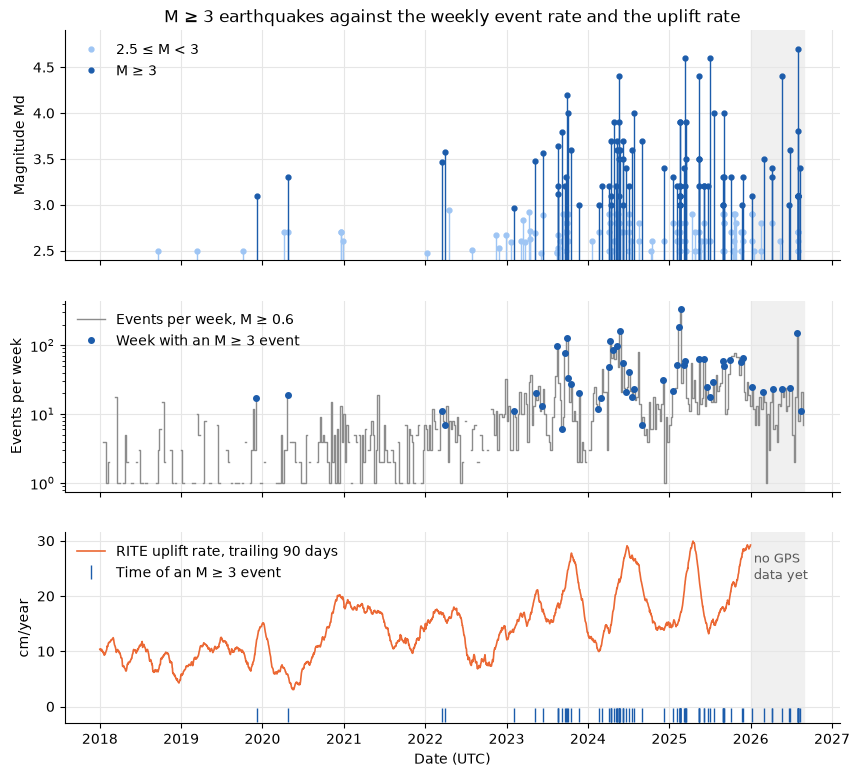

In [16]:
fig, (ax_m, ax_n, ax_r) = plt.subplots(3, 1, figsize=(10, 9), sharex=True,
                                       gridspec_kw={"height_ratios": [1.2, 1, 1]})

# Top: each event with M >= 2.5 as a stem; M >= 3 in dark blue.
for subset, colour, label in [(medium, "#9ec5f4", "2.5 ≤ M < 3"), (big, "#1c5cab", "M ≥ 3")]:
    subset = subset[(subset["time"] >= "2018-01-01") & (subset["time"] < end_complete)]
    ax_m.vlines(subset["time"], 2.4, subset["md"], color=colour, linewidth=1)
    ax_m.plot(subset["time"], subset["md"], "o", markersize=3.5, color=colour, label=label)
ax_m.set_ylim(2.4, 4.9)
ax_m.set_ylabel("Magnitude Md")
ax_m.set_title("M ≥ 3 earthquakes against the weekly event rate and the uplift rate")
ax_m.legend(frameon=False, loc="upper left")

# Middle: weekly counts at M >= Mc; weeks with an M >= 3 event marked.
ax_n.plot(weeks_18.index, weeks_18.where(weeks_18 > 0), drawstyle="steps-post", linewidth=1,
          color="0.55", label=f"Events per week, M ≥ {MC_MAIN}")
marked = weeks_18[big_weeks.reindex(weeks_18.index, fill_value=0) > 0]
ax_n.plot(marked.index + pd.Timedelta(days=3), marked, "o", markersize=4, color="#1c5cab",
          label="Week with an M ≥ 3 event")
ax_n.set_yscale("log")
ax_n.set_ylabel("Events per week")
ax_n.legend(frameon=False, loc="upper left")

# Bottom: RITE uplift rate, with a tick at the time of each M >= 3 event.
rite_rate_90 = trailing_rate(station_daily(gps, "RITE"), 90) * 100
ax_r.plot(rite_rate_90["2018":].index, rite_rate_90["2018":], linewidth=1.2, color="#eb6834",
          label="RITE uplift rate, trailing 90 days")
ax_r.plot(big["time"], np.full(len(big), -1.5), "|", markersize=10, color="#1c5cab",
          label="Time of an M ≥ 3 event")
ax_r.set_ylabel("cm/year")
ax_r.set_xlabel("Date (UTC)")
ax_r.legend(frameon=False, loc="upper left")

for ax in (ax_m, ax_n, ax_r):
    ax.axvspan(pd.Timestamp("2026-01-01", tz="UTC"), pd.Timestamp(end_complete, tz="UTC"),
               color="0.94", zorder=0)
    ax.grid(True, which="major", color="0.9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
ax_r.text(pd.Timestamp("2026-01-15", tz="UTC"), 28, "no GPS\ndata yet", fontsize=9, color="0.35", va="top")
plt.show()

**Is an M ≥ 3 more likely after a busy week, or after fast uplift?** For each week from 2019, did it contain an M ≥ 3 event, split by what the *previous* week looked like. These are the kinds of information a forecast for next week could use. (Uplift rates only to December 2025.)

In [17]:
weekly = pd.DataFrame({"count": weeks_18, "has_m3": big_weeks.reindex(weeks_18.index, fill_value=0) > 0})
weekly["count_prev_week"] = weekly["count"].shift(1)
weekly["uplift_rate_prev_week"] = on_weekday(rite_rate_90, weekly.index, 6).shift(1)
weekly = weekly[weekly.index >= "2019-01-07"]

def share_with_m3(by, bins, labels):
    groups = weekly.groupby(pd.cut(weekly[by], bins, labels=labels), observed=True)["has_m3"]
    return pd.DataFrame({"weeks": groups.size(), "weeks with M ≥ 3": groups.sum(),
                         "share": groups.mean().round(3)})

print("By the same week's number of events (M ≥ 0.6), for comparison:")
display(share_with_m3("count", [-1, 4, 19, 49, np.inf], ["0–4", "5–19", "20–49", "50+"]))
print("By the previous week's number of events (M ≥ 0.6):")
display(share_with_m3("count_prev_week", [-1, 4, 19, 49, np.inf], ["0–4", "5–19", "20–49", "50+"]))
print("By RITE's uplift rate at the end of the previous week (to Dec 2025):")
display(share_with_m3("uplift_rate_prev_week", [-np.inf, 10, 15, 20, np.inf],
                      ["< 10 cm/yr", "10–15", "15–20", "> 20"]))

By the same week's number of events (M ≥ 0.6), for comparison:


,weeks,weeks with M ≥ 3,share
count,,,
0–4,169,0,0.000
5–19,149,13,0.087
20–49,51,17,0.333
50+,30,21,0.700


By the previous week's number of events (M ≥ 0.6):


,weeks,weeks with M ≥ 3,share
count_prev_week,,,
0–4,170,5,0.029
5–19,148,25,0.169
20–49,51,12,0.235
50+,30,9,0.300


By RITE's uplift rate at the end of the previous week (to Dec 2025):


,weeks,weeks with M ≥ 3,share
uplift_rate_prev_week,,,
< 10 cm/yr,71,1,0.014
10–15,115,10,0.087
15–20,120,16,0.133
> 20,59,17,0.288


**How often is an event M ≥ 3, compared with Gutenberg–Richter?** If magnitudes followed one Gutenberg–Richter line from Mc = 0.6, the share of events with M ≥ 3 would be 10^(−b × (3 − 0.55)), using the lower bin edge 0.55. With b = 0.83 (the 2022–2026 value from M ≥ 0.5) that is 0.9%; with b = 0.70 (the value from larger events, `01_completeness` step 4) it is 1.9%.

In [18]:
in_range = events[(events["time"] >= "2019-01-01") & (events["time"] < "2026-09-01")]
mb = bin_magnitudes(in_range["md"])
year_of = in_range["time"].dt.year
share = pd.DataFrame({
    "M ≥ 0.6": (mb >= MC_MAIN - 1e-9).groupby(year_of).sum(),
    "M ≥ 3": (mb >= 3.0 - 1e-9).groupby(year_of).sum(),
})
share["share M ≥ 3 (%)"] = (100 * share["M ≥ 3"] / share["M ≥ 0.6"]).round(2)
for b in [0.83, 0.70]:
    share[f"G–R with b = {b} (%)"] = round(100 * 10 ** (-b * (3 - 0.55)), 2)
share

,M ≥ 0.6,M ≥ 3,share M ≥ 3 (%),G–R with b = 0.83 (%),G–R with b = 0.7 (%)
time,,,,,
2019,89,1,1.12,0.93,1.93
2020,142,1,0.70,0.93,1.93
2021,171,0,0.00,0.93,1.93
2022,295,2,0.68,0.93,1.93
2023,922,13,1.41,0.93,1.93
2024,1445,25,1.73,0.93,1.93
2025,2204,34,1.54,0.93,1.93
2026,588,15,2.55,0.93,1.93


**What plot 5 shows:**

- **Few positive cases.** 91 events with M ≥ 3, all since December 2019 and almost all since 2023, in only 51 of 399 weeks (13%). With GPS data (to December 2025) it's 76 events. A model for P(M ≥ 3 in 7 days) will learn from a few dozen positive weeks, nearly all in 2023–2025, so its evaluation will be noisy, and it can't be tested on the quiet years at all.
- **Large events come in clusters**, in the busiest weeks: in the same week, 70% of weeks with 50+ events at M ≥ 0.6 contain an M ≥ 3, but none of the weeks with 0–4 events. (Partly circular: an M ≥ 3 brings its own aftershocks.)
- **Looking one week ahead, both kinds of information help.** After a quiet previous week (0–4 events) only 3% of weeks have an M ≥ 3; after a busy one (50+) 30%. After uplift slower than 10 cm/year, 1%; faster than 20 cm/year, 29%. Both splits are partly the long-term trend again (busier, faster years have more large events), so phase 6 must check whether either adds anything once the trend is accounted for.
- **The uplift rate has pulsed roughly once or twice a year since 2023**, peaking at 25–30 cm/year (late 2023, spring 2024, spring 2025, end of 2025). Clusters of M ≥ 3 events tend to fall in the rising part of these pulses, but there are also M ≥ 3 events at lower rates (for example mid-2025). Note the trailing 90-day rate peaks several weeks after the actual uplift pulse (plot 4).
- **M ≥ 3 is more common than one Gutenberg–Richter line from small events predicts.** From 2023 to 2025, 1.4–1.7% of events with M ≥ 0.6 reach M ≥ 3; b = 0.83 would give 0.9%, b = 0.70 gives 1.9%. This is the bend found in `01_completeness`. 2026 so far is even higher (2.6%) despite fewer events. For phase 6: a model that turns a forecast count into P(M ≥ 3) with b ≈ 0.83 would underpredict by roughly half; using b ≈ 0.7, or modelling M ≥ 3 directly, is safer.

## 6. Where the earthquakes are, and where the stations are

Located events with M ≥ 0.6 (6,136 of 6,161: almost every event above Mc has a location), with the 21 GPS stations. Station coordinates come from Table 1 of De Martino et al. (2021), stored in `data/reference/gps_stations.csv` (see the README there). The map uses plain longitude and latitude, with the axes scaled so that 1 km is the same length in both directions. The coastline, lakes and place names in faint grey come from OpenStreetMap (`src/basemap.py`; downloaded by `scripts/download_data.py`).

One located event lies far outside the caldera (26 Nov 2020, near Vesuvius, the reused EventID 1057); it is left off the map.

6,135 located events with M ≥ 0.6 on the map. Median location since 2018: 40.827 N, 14.137 E


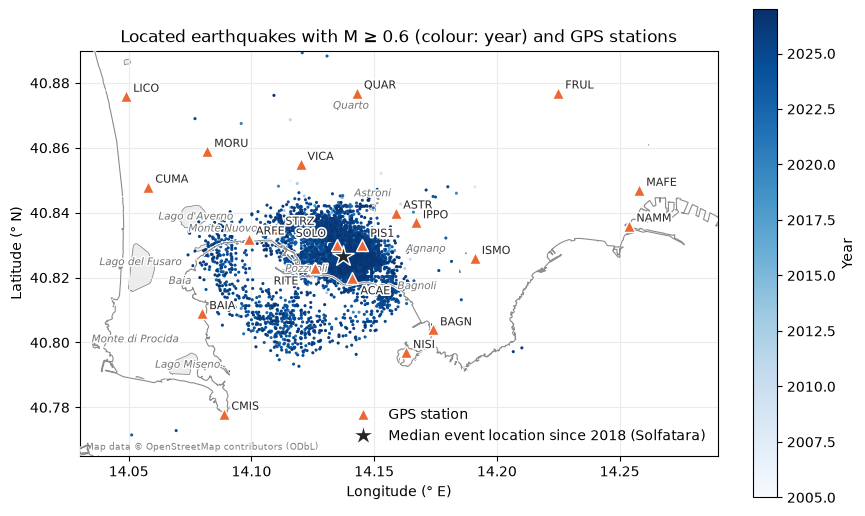

In [19]:
stations_xy = load_station_coordinates("../data/reference/gps_stations.csv")
located_mc = events[events["has_location"] & (bin_magnitudes(events["md"]) >= MC_MAIN - 1e-9)]
located_mc = located_mc[located_mc["longitude"] < 14.3]  # drop the event near Vesuvius
centre = located_mc.loc[located_mc["time"] >= "2018-01-01", ["latitude", "longitude"]].median()
print(f"{len(located_mc):,} located events with M ≥ {MC_MAIN} on the map. "
      f"Median location since 2018: {centre['latitude']:.3f} N, {centre['longitude']:.3f} E")

fig, ax = plt.subplots(figsize=(9, 7))
# Solfatara sits under the centre star, so it is named in the legend instead.
draw_basemap(ax, load_osm_features("../data/raw/osm/campi_flegrei_features.json"),
             labels=[n for n in DEFAULT_LABELS if n != "Solfatara"], offsets={"Quarto": (0, -10)})
order_by_time = located_mc.sort_values("time")
points = ax.scatter(order_by_time["longitude"], order_by_time["latitude"],
                    c=order_by_time["time"].dt.year + order_by_time["time"].dt.day_of_year / 366,
                    cmap="Blues", vmin=2005, vmax=2027, s=5, edgecolors="none")
ax.plot(stations_xy["longitude"], stations_xy["latitude"], "^", markersize=8, color="#eb6834",
        markeredgecolor="white", zorder=5, label="GPS station")
# Hand-placed labels for the crowded stations at the centre; the rest go up and right.
label_offsets = {"SOLO": (-30, 6), "PIS1": (6, 6), "RITE": (-30, -12), "ACAE": (6, -12)}
for name, row in stations_xy.iterrows():
    ax.annotate(name, (row["longitude"], row["latitude"]), textcoords="offset points",
                xytext=label_offsets.get(name, (5, 3)), fontsize=8, color="0.15", zorder=6,
                path_effects=[patheffects.withStroke(linewidth=2.5, foreground="white")])
ax.plot(centre["longitude"], centre["latitude"], "*", markersize=16, color="0.15",
        markeredgecolor="white", zorder=6, label="Median event location since 2018 (Solfatara)")

ax.set_xlim(14.03, 14.29)
ax.set_ylim(40.765, 40.89)
ax.set_aspect(1 / np.cos(np.radians(40.83)))  # 1 km east = 1 km north on screen
ax.set_xlabel("Longitude (° E)")
ax.set_ylabel("Latitude (° N)")
ax.set_title(f"Located earthquakes with M ≥ {MC_MAIN} (colour: year) and GPS stations")
ax.grid(True, which="major", color="0.92", linewidth=0.8)
ax.set_axisbelow(True)  # grid under the points, or it draws false edges on dense clusters
ax.legend(frameon=False, loc="lower right")
fig.colorbar(points, ax=ax, label="Year", fraction=0.035)
fig.savefig(FIGURES + "map_events_stations.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
# How far from the median location do events lie, year by year?
from_centre = distance_km(located_mc["latitude"], located_mc["longitude"],
                          centre["latitude"], centre["longitude"])
by_year = from_centre.groupby(located_mc["time"].dt.year)
pd.DataFrame({"events": by_year.size(), "median_km": by_year.median().round(2),
              "90th_percentile_km": by_year.quantile(0.9).round(2)}).loc[2014:]

,events,median_km,90th_percentile_km
time,,,
2014,15,0.90,1.81
2015,24,0.93,1.64
2016,30,0.65,1.46
2017,26,1.03,1.59
2018,80,0.77,1.40
2019,89,0.77,2.00
2020,140,0.65,1.42
2021,171,0.92,2.38
2022,294,0.87,2.05


**Depth over time.** Each located event with M ≥ 0.6 by depth, with the yearly median.

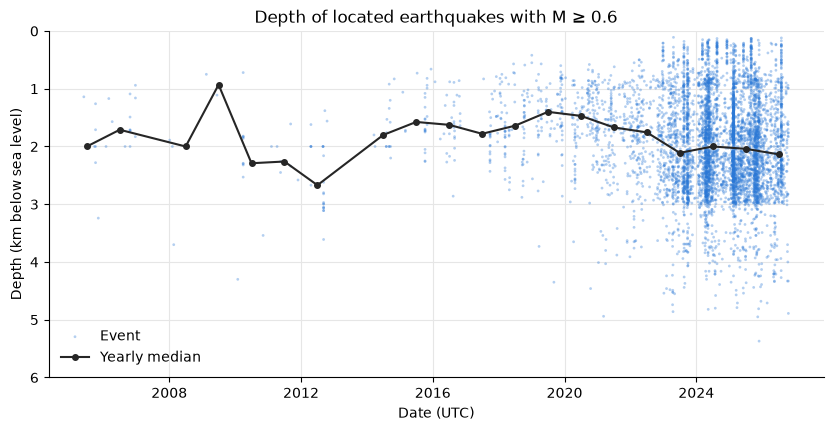

Deeper than 6 km (off the plot): 2 events
Events per 0.05 km of depth around 3 km:
depth_km
(2.75, 2.8]    118
(2.8, 2.85]    110
(2.85, 2.9]     99
(2.9, 2.95]    103
(2.95, 3.0]     94
(3.0, 3.05]     30
(3.05, 3.1]     19
(3.1, 3.15]     15
(3.15, 3.2]     20
(3.2, 3.25]     12


In [21]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(located_mc["time"], located_mc["depth_km"], s=4, color="#2a78d6", alpha=0.35,
           edgecolors="none", label="Event")
yearly_depth = located_mc.groupby(located_mc["time"].dt.year)["depth_km"].median()
ax.plot(pd.to_datetime(yearly_depth.index.astype(str) + "-07-01", utc=True), yearly_depth.values,
        "o-", color="0.15", linewidth=1.5, markersize=4, label="Yearly median")
ax.invert_yaxis()
ax.set_ylim(6, 0)
ax.set_axisbelow(True)
ax.set_ylabel("Depth (km below sea level)")
ax.set_xlabel("Date (UTC)")
ax.set_title(f"Depth of located earthquakes with M ≥ {MC_MAIN}")
ax.grid(True, which="major", color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left")
plt.show()
print(f"Deeper than 6 km (off the plot): {(located_mc['depth_km'] > 6).sum()} events")
depth_bins = pd.cut(located_mc["depth_km"], np.arange(2.75, 3.30, 0.05).round(2))
print("Events per 0.05 km of depth around 3 km:")
print(depth_bins.value_counts().sort_index().to_string())

**Distance from the seismicity, and uplift.** For each station: its distance from the median event location, and how much it rose from January 2018 to the end of its record (the order used in plot 2).

In [22]:
station_table = pd.DataFrame({
    "distance_from_events_km": distance_km(stations_xy["latitude"], stations_xy["longitude"],
                                           centre["latitude"], centre["longitude"]).round(1),
    "uplift_since_2018_cm": (uplift_since_2018 * 100).round(1),
}).sort_values("distance_from_events_km")
print(f"Correlation between distance and uplift since 2018: "
      f"{station_table.corr().iloc[0, 1]:.2f}")
station_table

Correlation between distance and uplift since 2018: -0.75


,distance_from_events_km,uplift_since_2018_cm
station,,
SOLO,0.4,71.6
PIS1,0.7,65.8
ACAE,0.8,31.6
RITE,1.0,115.4
ASTR,2.3,26.2
STRZ,2.4,67.5
IPPO,2.7,20.1
ARFE,3.3,50.1
VICA,3.5,20.2


**What plot 6 shows:**

- **The seismicity is very concentrated.** Since 2018 the median location is at 40.827 N, 14.137 E, in the Solfatara–Pisciarelli area. Every year since 2014, half the events lie within 0.65–1.0 km of it. **The core stays put, but the edge has grown:** 90% of events were within 1.4–2.0 km until 2020, and within about 3 km since 2023, reaching south into the Gulf of Pozzuoli and west towards ARFE (table above).
- **Depths are shallow: mostly 0.5–3.5 km**, with a yearly median of 1.4–2.1 km since 2015, slightly deeper (about 2 km) since 2023.
- **Two quirks of the locations, not of the volcano:**
  - There's a sharp step at 3.0 km depth: about 100 events per 0.05 km just above it, 12–30 just below (table above). Probably a feature of the location method (for example a layer boundary in the velocity model), not a real floor to the seismicity. Depth-based features should use broad bins, not fine depths.
  - Some coordinates repeat exactly (for example 18 events at latitude 40.8345), so locations are slightly quantised.
- **The centre of uplift is not the centre of seismicity.** The largest uplift is at RITE (115 cm since 2018), about 1 km south-west of the seismic centre; SOLO and PIS1, closer to the seismicity, rose less (66–72 cm). Uplift falls with distance (correlation −0.75), from about 1 m near the centre to under 1 cm at 9–10 km (LICO, FRUL, NAMM, MAFE). ACAE's value is low only because its record stops in 2021.
- **For phase 6:** stations within about 4 km (SOLO, PIS1, RITE, STRZ, ARFE, IPPO, ASTR) carry the deformation signal; the far ones (LICO, FRUL, NAMM, MAFE) mainly carry noise and network-wide effects, which could even be useful for removing common noise from the near stations.